# Laboratorio de clasificación 3

|                |                  |
:----------------|------------------|
| **Nombre**     | Omar Mendoza     |
| **Fecha**      | 18/10/2026       |
| **Expediente** | 757806           |

Una regresión logística simple toma **P** predictores y usa una función no lineal para convertir la respuesta binaria **Y** en probabilidades entre $0$ y $1$.

La visualización de este escenario es puntos separados por una línea recta.

<center><img src="https://wirelesspi.com/wp-content/uploads/2022/08/figure-logistic-regression-decision-boundary-2-570x550.png"></center>

Para casos donde los datos no son linealmente separables usamos el truco del kernel para mapear los datos a un espacio de Hilbert.

Imagina un escenario donde tienes dos predictores $x_1, x_2$ y la salida de estos predictores se comporta de esta manera:

| **$x_1$** | **$x_2$** | Salida |
:-----------|-----------|--------|
| 0         | 0         | 0      |
| 0         | 1         | 1      |
| 1         | 0         | 1      |
| 1         | 1         | 0      |


Imagínalo como el interruptos de luz de un foco en una escalera. Se puede prender y apagar desde arriba y desde abajo.

<center><img src="https://www.researchgate.net/profile/Brian-Spears/publication/322048911/figure/fig4/AS:667820685807618@1536232267250/The-exclusive-or-XOR-function-is-a-nonlinear-function-that-returns-0-when-its-two.png"></center>

¿Cómo podemos separar estos datos usando sólo regresión logística? Sin importar cómo usemos una sola línea, nunca se van a poder separar todos los casos, por lo que tendríamos situaciones donde siempre habría error. 

Solución: ¿Por qué nos estamos limitando a una sola línea?

<center><img src="https://pabloinsente.github.io/assets/post-5/XOR-linear.png"></center>

La regresión logística sola es un método de aprendizaje estadístico convexo. Combinar dos regresiones logísticas para clasificar datos no linealmente separables convierte el problema a uno no convexo. ¿Por qué?

Porque la salida de una logistica entra a la otra, y al juntar funciones no lineales el error ya no tiene forma de tazon. Ademas las dos neuronas de en medio se pueden intercambiar y el modelo da lo mismo, entonces hay mas de un minimo

¿Qué significa que una función sea convexa?

Que tiene forma de tazon y solo tiene un fondo. Si unes dos puntos de la grafica con una linea recta, la linea queda arriba de la funcion. Por ejemplo x al cuadrado

¿Por qué nos importa que una función sea convexa o no? ¿Qué impacto tiene para los resultados?

Si es convexa el minimo que encuentras es el mejor y siempre llegas al mismo resultado. Si no es convexa te puedes quedar atorado en un minimo local y el resultado cambia segun como empiece, por eso se fija el random_state

## Ejercicio 1

Utilizaremos el clasificador `MLPClassifier` de la librería `sklearn`.

Entra a la documentación y describe cómo funciona este objeto (qué entradas necesita, qué salidas da, descripción de sus hiperparámetros).

Es una red neuronal, varias capas de neuronas donde cada una es como una regresion logistica que recibe lo que sale de la capa anterior

Entradas: fit(X, y) con los datos y las clases, conviene escalar los datos antes

Salidas: predict da la clase y predict_proba la probabilidad de cada clase. Tambien guarda los pesos en coefs_ y cuantas iteraciones hizo en n_iter_

Hiperparametros:

- hidden_layer_sizes: cuantas capas y neuronas, default (100,) que es una capa de 100
- activation: la funcion de cada neurona, relu (default), logistic, tanh o identity
- solver: como busca los pesos, adam (default), sgd o lbfgs
- alpha: penalizacion L2 como en ridge, default 0.0001
- learning_rate_init: tamaño del paso, default 0.001
- max_iter: maximo de iteraciones, default 200
- early_stopping: si es True se detiene cuando deja de mejorar
- random_state: para que salga igual cada vez

## Ejercicio 2

Utiliza el objeto de perceptrón multicapa para clasificar si un tumor es maligno o benigno con el dataset `Brain Tumor Dataset`. Utiliza un cross-validation de train-test de 70/30. Sigue todos los pasos de EDA y limpieza vistos.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score, confusion_matrix

In [2]:
datos = pd.read_csv("brain_tumor_dataset.csv")

print(datos.shape)
datos.head()

(20000, 19)


,Patient_ID,Age,Gender,Tumor_Type,Tumor_Size,Location,Histology,Stage,Symptom_1,Symptom_2,Symptom_3,Radiation_Treatment,Surgery_Performed,Chemotherapy,Survival_Rate,Tumor_Growth_Rate,Family_History,MRI_Result,Follow_Up_Required
0,1,73,Male,Malignant,5.375612,Temporal,Astrocytoma,III,Vision Issues,Seizures,Seizures,No,No,No,51.312579,0.111876,No,Positive,Yes
1,2,26,Male,Benign,4.847098,Parietal,Glioblastoma,II,Headache,Headache,Nausea,Yes,Yes,Yes,46.373273,2.165736,Yes,Positive,Yes
2,3,31,Male,Benign,5.588391,Parietal,Meningioma,I,Vision Issues,Headache,Seizures,No,No,No,47.072221,1.884228,No,Negative,No
3,4,29,Male,Malignant,1.436600,Temporal,Medulloblastoma,IV,Vision Issues,Seizures,Headache,Yes,No,Yes,51.853634,1.283342,Yes,Negative,No
4,5,54,Female,Benign,2.417506,Parietal,Glioblastoma,I,Headache,Headache,Seizures,No,No,Yes,54.708987,2.069477,No,Positive,Yes


In [3]:
datos.dtypes

Patient_ID               int64
Age                      int64
Gender                  object
Tumor_Type              object
Tumor_Size             float64
Location                object
Histology               object
Stage                   object
Symptom_1               object
Symptom_2               object
Symptom_3               object
Radiation_Treatment     object
Surgery_Performed       object
Chemotherapy            object
Survival_Rate          float64
Tumor_Growth_Rate      float64
Family_History          object
MRI_Result              object
Follow_Up_Required      object
dtype: object

In [4]:
print("Nulos:", datos.isna().sum().sum())
print("Duplicados:", datos.duplicated().sum())

Nulos: 0
Duplicados: 0


In [5]:
datos.nunique()

Patient_ID             20000
Age                       60
Gender                     2
Tumor_Type                 2
Tumor_Size             20000
Location                   4
Histology                  4
Stage                      4
Symptom_1                  4
Symptom_2                  4
Symptom_3                  4
Radiation_Treatment        2
Surgery_Performed          2
Chemotherapy               2
Survival_Rate          20000
Tumor_Growth_Rate      20000
Family_History             2
MRI_Result                 2
Follow_Up_Required         2
dtype: int64

In [6]:
for columna in ["Gender", "Tumor_Type", "Location", "Histology", "Stage", "Symptom_1", "MRI_Result"]:
    print(columna, datos[columna].unique())

Gender ['Male' 'Female']
Tumor_Type ['Malignant' 'Benign']
Location ['Temporal' 'Parietal' 'Frontal' 'Occipital']
Histology ['Astrocytoma' 'Glioblastoma' 'Meningioma' 'Medulloblastoma']
Stage ['III' 'II' 'I' 'IV']
Symptom_1 ['Vision Issues' 'Headache' 'Seizures' 'Nausea']
MRI_Result ['Positive' 'Negative']


Son 20000 pacientes y 19 columnas, sin nulos ni duplicados. Las categoricas vienen bien escritas y tienen 2 o 4 valores. Patient_ID no sirve para predecir porque es un numero distinto para cada paciente

In [7]:
datos["Tumor_Type"].value_counts()

Tumor_Type
Malignant    10030
Benign        9970
Name: count, dtype: int64

In [8]:
datos.describe()

,Patient_ID,Age,Tumor_Size,Survival_Rate,Tumor_Growth_Rate
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,10000.500000,49.433700,5.236552,70.131699,1.547701
std,5773.647028,17.389296,2.754359,17.270834,0.835995
min,1.000000,20.000000,0.500410,40.002386,0.100017
25%,5000.750000,34.000000,2.836686,55.224439,0.830433
50%,10000.500000,49.000000,5.200675,70.305066,1.541821
75%,15000.250000,65.000000,7.624299,85.043395,2.262484
max,20000.000000,79.000000,9.999420,99.998125,2.999835


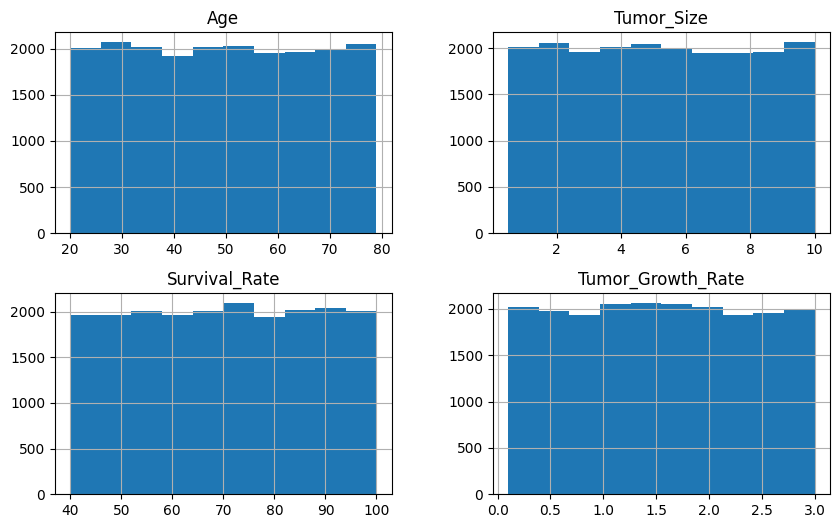

In [9]:
numericas = ["Age", "Tumor_Size", "Survival_Rate", "Tumor_Growth_Rate"]

datos[numericas].hist(figsize=(10, 6))
plt.show()

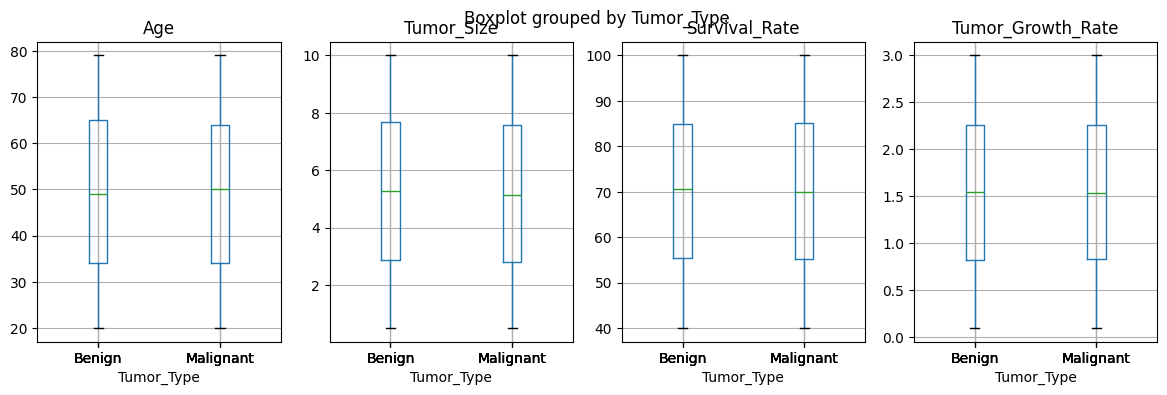

In [10]:
datos.boxplot(column=numericas, by="Tumor_Type", layout=(1, 4), figsize=(14, 4), sharey=False)
plt.show()

In [11]:
pd.crosstab(datos["Stage"], datos["Tumor_Type"], normalize="index")

Tumor_Type,Benign,Malignant
Stage,,
I,0.490172,0.509828
II,0.503043,0.496957
III,0.492631,0.507369
IV,0.508052,0.491948


In [12]:
pd.crosstab(datos["Histology"], datos["Tumor_Type"], normalize="index")

Tumor_Type,Benign,Malignant
Histology,,
Astrocytoma,0.498683,0.501317
Glioblastoma,0.499013,0.500987
Medulloblastoma,0.501908,0.498092
Meningioma,0.494418,0.505582


Hay casi los mismos malignos que benignos, 10030 contra 9970

Los histogramas salen planos y en las cajas benignos y malignos quedan iguales. En las tablas todos los grupos tienen como 50 por ciento de malignos, hasta la etapa IV. Ninguna columna separa las clases, parece un dataset hecho al azar

In [13]:
datos = datos.drop(columns="Patient_ID")

datos["Gender"] = (datos["Gender"] == "Male").astype(int)
datos["MRI_Result"] = (datos["MRI_Result"] == "Positive").astype(int)
datos["Tumor_Type"] = (datos["Tumor_Type"] == "Malignant").astype(int)
datos["Stage"] = datos["Stage"].map({"I": 1, "II": 2, "III": 3, "IV": 4})

for columna in ["Radiation_Treatment", "Surgery_Performed", "Chemotherapy", "Family_History", "Follow_Up_Required"]:
    datos[columna] = (datos[columna] == "Yes").astype(int)

datos.head()

,Age,Gender,Tumor_Type,Tumor_Size,Location,Histology,Stage,Symptom_1,Symptom_2,Symptom_3,Radiation_Treatment,Surgery_Performed,Chemotherapy,Survival_Rate,Tumor_Growth_Rate,Family_History,MRI_Result,Follow_Up_Required
0,73,1,1,5.375612,Temporal,Astrocytoma,3,Vision Issues,Seizures,Seizures,0,0,0,51.312579,0.111876,0,1,1
1,26,1,0,4.847098,Parietal,Glioblastoma,2,Headache,Headache,Nausea,1,1,1,46.373273,2.165736,1,1,1
2,31,1,0,5.588391,Parietal,Meningioma,1,Vision Issues,Headache,Seizures,0,0,0,47.072221,1.884228,0,0,0
3,29,1,1,1.436600,Temporal,Medulloblastoma,4,Vision Issues,Seizures,Headache,1,0,1,51.853634,1.283342,1,0,0
4,54,0,0,2.417506,Parietal,Glioblastoma,1,Headache,Headache,Seizures,0,0,1,54.708987,2.069477,0,1,1


Se quita Patient_ID, las de si o no se pasan a 0 y 1 y la etapa de 1 a 4. Tumor_Type queda 1 maligno y 0 benigno

In [14]:
X = datos.drop(columns="Tumor_Type")
y = datos["Tumor_Type"]

numerical_cols = ["Age", "Tumor_Size", "Survival_Rate", "Tumor_Growth_Rate", "Stage"]
categorical_cols = ["Location", "Histology", "Symptom_1", "Symptom_2", "Symptom_3"]
boolean_cols = ["Gender", "Radiation_Treatment", "Surgery_Performed", "Chemotherapy", "Family_History", "MRI_Result", "Follow_Up_Required"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(), categorical_cols),
        ("bool", "passthrough", boolean_cols),
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(X_train.shape, X_test.shape)

(14000, 17) (6000, 17)


In [15]:
pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("mlp", MLPClassifier(random_state=42))])

pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('mlp', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers

In [16]:
y_pred = pipeline.predict(X_test)
proba = pipeline.predict_proba(X_test)[:, 1]

print("Accuracy train:", accuracy_score(y_train, pipeline.predict(X_train)))
print("Accuracy test:", accuracy_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("AUC:", roc_auc_score(y_test, proba))

Accuracy train: 0.7170714285714286
Accuracy test: 0.5
Recall: 0.46642527978933507
Precision: 0.5067954220314735
F1: 0.48577305450805625
AUC: 0.4993396718317917


In [17]:
# renglones lo real, columnas lo predicho

confusion_matrix(y_test, y_pred)

array([[1583, 1379],
       [1621, 1417]])

En train saca 0.717 de accuracy pero en test 0.5, se aprendio los datos de memoria. El AUC es 0.499, igual que adivinar. De 3038 malignos solo detecto 1417, recall de 0.47

¿Qué métrico crees que sea mejor para este ejercicio? Escoge los 3 métricos que crees más apropiados para esta predicción, argumenta en pro y en contra del top 3. Elige uno para optimizar (justifica tu respuesta).

Recall: cuantos malignos detecta. Es el mas importante porque lo peor es decirle a alguien que su tumor es benigno cuando no. En contra, si dices que todo es maligno sacas recall de 1

AUC: que tan bien separa malignos de benignos sin depender del umbral. A favor que no se puede inflar, decir todo de una clase da 0.5. En contra que no dice cuantos malignos se te pasan

F1: junta recall y precision. A favor que tambien toma en cuenta las falsas alarmas. En contra que trata igual los dos errores y aqui el falso negativo es peor

Escojo optimizar el AUC, porque si optimizo el recall gana el modelo que dice que todo es maligno. Con el mejor AUC despues se puede bajar el umbral para subir el recall

## Ejercicio 3

Modifica los hiperparámetros para elevar el métrico elegido. Intenta con 10 sets de hiperparámetros distintos. Crea una tabla que muestre los resultados.

In [18]:
modelos = {
    "default": MLPClassifier(random_state=42),
    "10 neuronas": MLPClassifier(hidden_layer_sizes=(10,), random_state=42),
    "2 capas de 50 y 20": MLPClassifier(hidden_layer_sizes=(50, 20), random_state=42),
    "activation logistic": MLPClassifier(activation="logistic", random_state=42),
    "activation tanh": MLPClassifier(activation="tanh", random_state=42),
    "alpha 1": MLPClassifier(alpha=1, random_state=42),
    "alpha 10": MLPClassifier(alpha=10, random_state=42),
    "learning rate 0.0001": MLPClassifier(learning_rate_init=0.0001, random_state=42),
    "early stopping": MLPClassifier(early_stopping=True, random_state=42),
    "sgd con 10 neuronas": MLPClassifier(hidden_layer_sizes=(10,), solver="sgd", learning_rate_init=0.01, random_state=42),
}

resultados = []

for nombre, mlp in modelos.items():
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("mlp", mlp)])
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    proba = pipeline.predict_proba(X_test)[:, 1]

    resultados.append({"modelo": nombre,
                       "AUC": roc_auc_score(y_test, proba),
                       "recall": recall_score(y_test, y_pred),
                       "accuracy": accuracy_score(y_test, y_pred)})

pd.DataFrame(resultados).sort_values("AUC", ascending=False).round(4)

,modelo,AUC,recall,accuracy
3,activation logistic,0.5062,0.5836,0.5077
5,alpha 1,0.5031,0.3144,0.4963
6,alpha 10,0.5007,0.0000,0.4937
0,default,0.4993,0.4664,0.5000
2,2 capas de 50 y 20,0.4981,0.4974,0.5003
7,learning rate 0.0001,0.4978,0.5599,0.5032
1,10 neuronas,0.4960,0.5537,0.4970
8,early stopping,0.4944,0.5513,0.4957
9,sgd con 10 neuronas,0.4940,0.5734,0.4920
4,activation tanh,0.4925,0.5016,0.4945


Todas quedan entre 0.49 y 0.51 de AUC, pegadas al 0.5. La mejor fue activation logistic con 0.506 pero esa diferencia es ruido

Con alpha de 10 la red dice que todo es benigno y el recall sale 0, pero su AUC sigue en 0.5, por eso escogi el AUC

Mover hiperparametros no sirve si los datos no traen informacion, el EDA ya lo decia